# Dataset Inspection

In [ ]:
from pathlib import Path

REPO_DIR = Path.cwd()
while not (REPO_DIR / 'pyproject.toml').exists():
    REPO_DIR = REPO_DIR.parent
print(f'Repository root: {REPO_DIR}')

Repository root: /home/andreas/workspaces/brainweb-mri-denoising-benchmark


In [10]:
from pathlib import Path
import matplotlib.pyplot as plt
from brainweb_denoising.io import load_nifti, volume_metadata
from brainweb_denoising.visualization import orthogonal_slices

In [11]:
NIFTI_DIR = (REPO_DIR / 'data/raw/nifti')

=== T1 ===
{'dimensions': (181, 217, 181), 'voxel_spacing_mm': (1.0, 1.0, 1.0), 'data_type': 'float32', 'intensity_range': (7.511735916447548e-13, 1196.6468505859375), 'affine': array([[   1.,    0.,    0.,  -90.],
       [   0.,    1.,    0., -126.],
       [   0.,    0.,    1.,  -72.],
       [   0.,    0.,    0.,    1.]]), 'qform': None, 'qform_code': 0, 'sform': array([[   1.,    0.,    0.,  -90.],
       [   0.,    1.,    0., -126.],
       [   0.,    0.,    1.,  -72.],
       [   0.,    0.,    0.,    1.]]), 'sform_code': 1, 'orientation': ('R', 'A', 'S')}


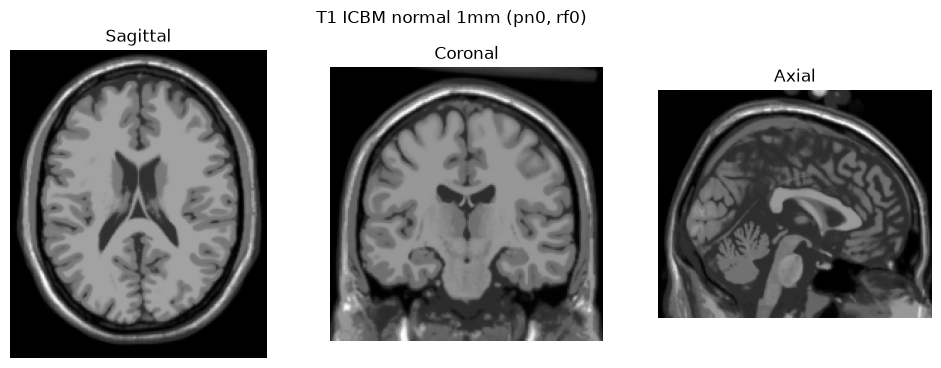

=== T2 ===
{'dimensions': (181, 217, 181), 'voxel_spacing_mm': (1.0, 1.0, 1.0), 'data_type': 'float32', 'intensity_range': (7.771561172376096e-12, 4741.6650390625), 'affine': array([[   1.,    0.,    0.,  -90.],
       [   0.,    1.,    0., -126.],
       [   0.,    0.,    1.,  -72.],
       [   0.,    0.,    0.,    1.]]), 'qform': None, 'qform_code': 0, 'sform': array([[   1.,    0.,    0.,  -90.],
       [   0.,    1.,    0., -126.],
       [   0.,    0.,    1.,  -72.],
       [   0.,    0.,    0.,    1.]]), 'sform_code': 1, 'orientation': ('R', 'A', 'S')}


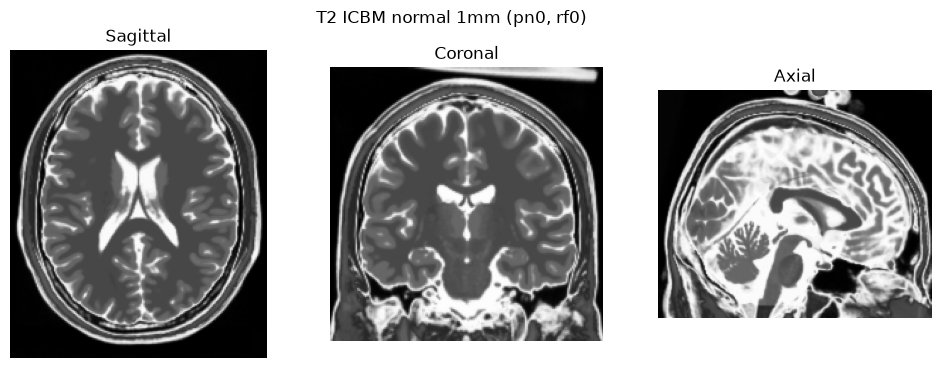

=== PD ===
{'dimensions': (181, 217, 181), 'voxel_spacing_mm': (1.0, 1.0, 1.0), 'data_type': 'float32', 'intensity_range': (1.583696368490095e-11, 6135.9609375), 'affine': array([[   1.,    0.,    0.,  -90.],
       [   0.,    1.,    0., -126.],
       [   0.,    0.,    1.,  -72.],
       [   0.,    0.,    0.,    1.]]), 'qform': None, 'qform_code': 0, 'sform': array([[   1.,    0.,    0.,  -90.],
       [   0.,    1.,    0., -126.],
       [   0.,    0.,    1.,  -72.],
       [   0.,    0.,    0.,    1.]]), 'sform_code': 1, 'orientation': ('R', 'A', 'S')}


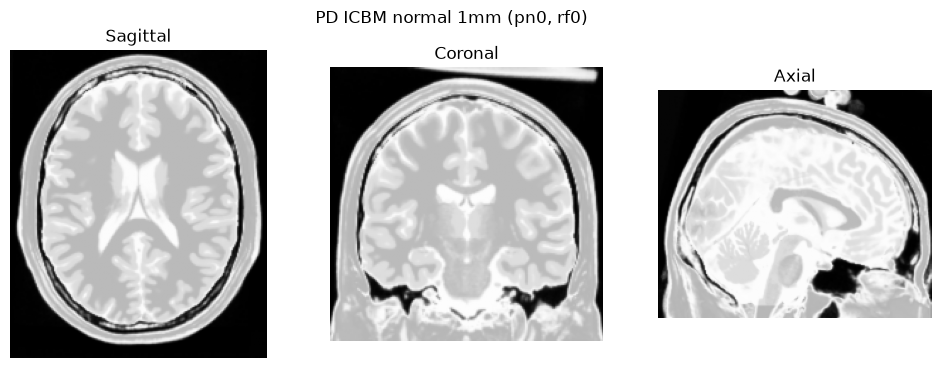

54 volumes, all on the same grid: True


In [12]:
# Print Metadata for the Three Clean Contrasts (T1/T2/PD with pn0_rf0).
for contrast in ('T1', 'T2', 'PD'):
    path = NIFTI_DIR / f'{contrast}_ICBM_normal_1mm_pn0_rf0.nii.gz'
    image = load_nifti(path)
    print(f'=== {contrast} ===')
    print(volume_metadata(image))
    orthogonal_slices(image.get_fdata())
    plt.gcf().suptitle(f'{contrast} ICBM normal 1mm (pn0, rf0)')
    plt.savefig(f'{REPO_DIR}/results/figures/inspection_{contrast}_pn0_rf0.png', dpi=150, bbox_inches='tight')
    plt.show()

# Check Consistency by Sweeping Across all Converted Volumes.
volumes = sorted(NIFTI_DIR.glob('*.nii.gz'))
reference = volume_metadata(load_nifti(volumes[0]))
consistent = all(
    volume_metadata(load_nifti(p))[k] == reference[k]
    for p in volumes for k in ('dimensions', 'voxel_spacing_mm', 'data_type', 'orientation')
)
print(f'{len(volumes)} volumes, all on the same grid: {consistent}')